# FIPE 2022

### Sobre os dados:

- Origem dos dados: FIPE
- Ano de referência: 2022
- Quantidade de dados 290.275 dados

### Perguntas:

1. A motorização dos carros tende a diminuir ao longo dos anos de fabricação?
2. Como se comporta o preço médio ao longo dos anos de fabricação?
3. Como se comporta o preço por motorização ao longo dos anos de fabricação?
4. Os carros manuais perderam mais valor se comparados aos automáticos?
5. A depreciação média ao longo dos anos é maior com marcas de alto padrão do que as de uso comum?
6. Como se comporta a depreciação média dos carros a gasolina em relação aos carros diesel?

### Hipóteses:

1. SIM
2. Tende a aumentar
3. Tende a diminuir pois a eficiência dos 1.0 3 cil é muito maior, então a demanda pra carros com motorização maior é menor.
4. Não, os automáticos devem perder mais valor pela durabilidade e manutenibilidade do câmbio, fatores importantes pra quem compra carro velho.
5. Sim, os carros de uso comum são mais comercializados e procurados. Dessa forma, carros de luxo antigo são consideradas "bombas" e a procura é baixa, também por falta de peças e necessidade de mão de obra especializada.
6. Não sei, mas acho que é menor em 2022, visto o preço do diesel.

In [ ]:
import pandas as pd

df = pd.read_csv("./fipe_2022.csv")

df.head()

,year_of_reference,month_of_reference,fipe_code,authentication,brand,model,fuel,gear,engine_size,year_model,avg_price_brl,age_years
0,2022,January,038001-6,vwmrywl5qs,Acura,NSX 3.0,Gasoline,manual,3.0,1995,43779.0,28
1,2022,January,038001-6,t9mt723qhz,Acura,NSX 3.0,Gasoline,manual,3.0,1994,42244.0,29
2,2022,January,038001-6,tr5wv4z21g,Acura,NSX 3.0,Gasoline,manual,3.0,1993,40841.0,30
3,2022,January,038001-6,s2xxsjz3mt,Acura,NSX 3.0,Gasoline,manual,3.0,1992,39028.0,31
4,2022,January,038001-6,rtm9gj7zk8,Acura,NSX 3.0,Gasoline,manual,3.0,1991,35678.0,32


### Separação LUXO vs POPULAR

In [ ]:
import numpy as np

x = np.sort(df.year_model.unique())[10:]
x_ = np.array(range(len(x))).reshape(-1, 1)

In [ ]:
# A depreciação é maior com marcas de luxo comparadas a marcas comuns?

# Vamos escolher 10 marcas comuns e 10 de luxo

df.brand.unique()

array(['Acura', 'Agrale', 'Alfa Romeo', 'AM Gen', 'Asia Motors',
       'ASTON MARTIN', 'Audi', 'Baby', 'BMW', 'BRM', 'CAB Motors',
       'Cadillac', 'CBT Jipe', 'CHANA', 'CHANGAN', 'Caoa Chery',
       'GM - Chevrolet', 'Chrysler', 'Citroën', 'Cross Lander', 'Daewoo',
       'Daihatsu', 'Dodge', 'EFFA', 'Engesa', 'Envemo', 'Ferrari', 'Fiat',
       'Fibravan', 'Ford', 'FOTON', 'Fyber', 'GEELY', 'GREAT WALL',
       'HAFEI', 'Honda', 'Hyundai', 'Isuzu', 'IVECO', 'JAC', 'Jaguar',
       'Jeep', 'JINBEI', 'JPX', 'Kia Motors', 'Lada', 'Land Rover',
       'Lexus', 'LIFAN', 'LOBINI', 'Lotus', 'Mahindra', 'Maserati',
       'Matra', 'Mazda', 'Mclaren', 'Mercedes-Benz', 'Mercury', 'MG',
       'MINI', 'Mitsubishi', 'Nissan', 'Peugeot', 'Plymouth', 'Pontiac',
       'Porsche', 'RAM', 'RELY', 'Renault', 'Rolls-Royce', 'Rover',
       'Saab', 'Saturn', 'Seat', 'SHINERAY', 'smart', 'SSANGYONG',
       'Subaru', 'Suzuki', 'TAC', 'Toyota', 'Troller', 'VW - VolksWagen',
       'Volvo', 'Wake', 'Wa

In [ ]:
# As marcas escolhidas devem ter uma quantidade razoável de modelos na tabela
brands = list(df.brand.unique())
brand_count = []
avg_price = []

for car_brand in brands:
    brand_count.append(len(df[df.brand == car_brand]))
    avg_price.append(df[df.brand == car_brand].avg_price_brl.mean())

print(len(brands))
print(len(brand_count))
print(len(avg_price))

86
86
86


In [ ]:
brands_df = pd.DataFrame({'brand':brands, 'brand_count':brand_count, 'avg_price':avg_price})
brands_df['price_per_count'] = brands_df.avg_price / brands_df.brand_count
brands_df.sort_values(by='avg_price', ascending=False, inplace=True)
brands_df.reset_index(inplace=True, drop=True)
brands_df.head(30)

,brand,brand_count,avg_price,price_per_count
0,Rolls-Royce,363,3.857727e+06,10627.346478
1,Mclaren,340,3.231483e+06,9504.362310
2,Ferrari,852,3.044625e+06,3573.503144
3,ASTON MARTIN,240,8.959112e+05,3732.963299
4,Porsche,6800,6.319960e+05,92.940584
5,Maserati,1367,5.077150e+05,371.408174
6,RAM,290,4.305816e+05,1484.764304
7,AM Gen,108,4.089208e+05,3786.303412
8,Land Rover,6973,2.784827e+05,39.937282
9,Jaguar,2788,2.732817e+05,98.020711


In [ ]:
brands_df.describe()

,brand_count,avg_price,price_per_count
count,86.000000,8.600000e+01,86.000000
mean,3375.290698,2.110308e+05,649.196738
std,6390.051981,6.253335e+05,1706.043818
min,24.000000,7.525833e+03,1.501227
25%,132.000000,2.656151e+04,25.306003
50%,378.000000,4.848215e+04,95.480648
75%,3439.000000,1.075484e+05,304.584320
max,28179.000000,3.857727e+06,10627.346478


In [ ]:
brands_df[(brands_df.brand_count >= 132) & (brands_df.price_per_count >= 25)].head(20)

,brand,brand_count,avg_price,price_per_count
0,Rolls-Royce,363,3.857727e+06,10627.346478
1,Mclaren,340,3.231483e+06,9504.362310
2,Ferrari,852,3.044625e+06,3573.503144
3,ASTON MARTIN,240,8.959112e+05,3732.963299
4,Porsche,6800,6.319960e+05,92.940584
5,Maserati,1367,5.077150e+05,371.408174
6,RAM,290,4.305816e+05,1484.764304
8,Land Rover,6973,2.784827e+05,39.937282
9,Jaguar,2788,2.732817e+05,98.020711
13,IVECO,991,2.051203e+05,206.983124


In [ ]:
# luxury = ['Rolls-Royce', 'Mclaren', 'ASTON MARTIN', 'Ferrari', 'RAM', 'GREAT WALL', 'Cadillac', 'Maserati', 'smart', 'Troller', 'Acura', 'LIFAN', 'Lexus', 'Mercedes-Benz', 'Audi', 'BMW', 'Land Rover', 'Porsche', 'Volvo', 'Jaguar', 'MINI', 'Chrysler', 'Maserati']
# common = ['GM - Chevrolet', 'VW - VolksWagen', 'Fiat', 'Ford', 'Renault', 'Peugeot', 'Toyota', 'Mitsubishi', 'Citroën', 'Hyundai']

luxury = brands_df[(brands_df.brand_count >= 132) & (brands_df.price_per_count >= 25)].brand.to_list()[0:10]
luxury.pop()
luxury.append('Lexus')
luxury

['Rolls-Royce',
 'Mclaren',
 'Ferrari',
 'ASTON MARTIN',
 'Porsche',
 'Maserati',
 'RAM',
 'Land Rover',
 'Jaguar',
 'Lexus']

In [ ]:
brands_df[(brands_df.brand_count >= 132) & (brands_df.price_per_count <= 25)].tail(21)

,brand,brand_count,avg_price,price_per_count
11,BMW,10060,233370.866799,23.197899
15,Audi,12168,171157.246959,14.066177
19,Volvo,6069,120358.283078,19.831650
24,Toyota,10309,92086.817538,8.932662
25,Mitsubishi,10182,85786.164113,8.425276
29,Nissan,6885,66779.522585,9.699277
30,Hyundai,7485,65562.466667,8.759181
32,Honda,5710,64742.028546,11.338359
34,Kia Motors,5473,60246.439247,11.007937
37,Suzuki,3867,56118.100595,14.512051


In [ ]:
# Apenas as ativas no Brasil em 2026

common = brands_df[(brands_df.brand_count >= 132) & (brands_df.price_per_count <= 25)].brand.to_list()[-15:]

for mark in ['Daewoo', 'Seat', 'Chrysler', 'Honda', 'Hyundai']:
    common.remove(mark)

common

['Kia Motors',
 'Suzuki',
 'Subaru',
 'GM - Chevrolet',
 'Ford',
 'Renault',
 'Citroën',
 'VW - VolksWagen',
 'Peugeot',
 'Fiat']

In [ ]:
len(df[df.brand.isin(common)])

155618

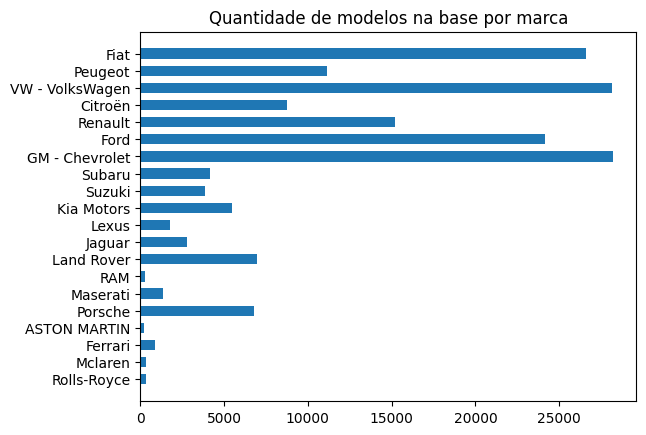

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


y_conj = luxury + common
x_conj = []

for brand_mark in y_conj:
    x_conj.append(len(df[df.brand == brand_mark]))

# x_brands = brands_df.brand[:24]
# y_brands = brands_df.brand_count[:24]

plt.barh(y_conj, x_conj, height=0.6)
plt.title('Quantidade de modelos na base por marca')
plt.show()

In [ ]:
# luxury = ['Mercedes-Benz', 'Audi', 'BMW', 'Land Rover', 'Porsche', 'Volvo', 'Jaguar', 'MINI', 'Chrysler', 'Maserati']
# common = ['GM - Chevrolet', 'VW - VolksWagen', 'Fiat', 'Ford', 'Renault', 'Peugeot', 'Toyota', 'Mitsubishi', 'Citroën', 'Hyundai']


df_luxury = df[df.brand.isin(luxury)]
df_common = df[df.brand.isin(common)]

print(len(df_luxury))
print(len(df_common))

21762
155618


In [ ]:
y_luxury, y_common = [], []

for year in x:
    y_luxury.append(df_luxury[df_luxury.year_model == year].avg_price_brl.mean())
    y_common.append(df_common[df_common.year_model == year].avg_price_brl.mean())

y_luxury = np.array(y_luxury).reshape(-1, 1)
y_common = np.array(y_common).reshape(-1, 1)

print(len(y_luxury))
print(len(y_common))

29
29


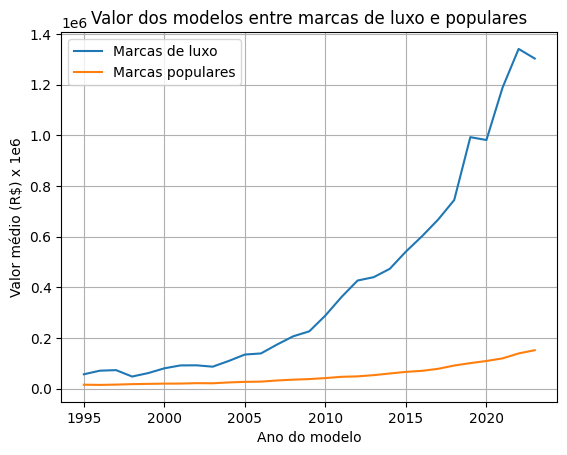

In [ ]:
plt.plot(x, y_luxury, label='Marcas de luxo')
plt.plot(x, y_common, label='Marcas populares')
plt.title('Valor dos modelos entre marcas de luxo e populares')
plt.xlabel('Ano do modelo')
plt.ylabel('Valor médio (R$) x 1e6')
plt.legend()
plt.grid()
plt.show()

Conclusão: as marcas de luxo são anomalias para a distribuição de carros de marcas populares e vice-versa: devem ser analisadas separadamente.

### Pergunta 1

In [ ]:
# A motorização dos carros tende a diminuir ao longo dos anos de fabricação?

import numpy as np
import matplotlib.pyplot as plt

y_lux = []
y_com = []

for year in x:
    y_lux.append(df_luxury[df_luxury.year_model == year].engine_size.mean())
    y_com.append(df_common[df_common.year_model == year].engine_size.mean())

y_lux = np.array(y_lux)
y_com = np.array(y_com)

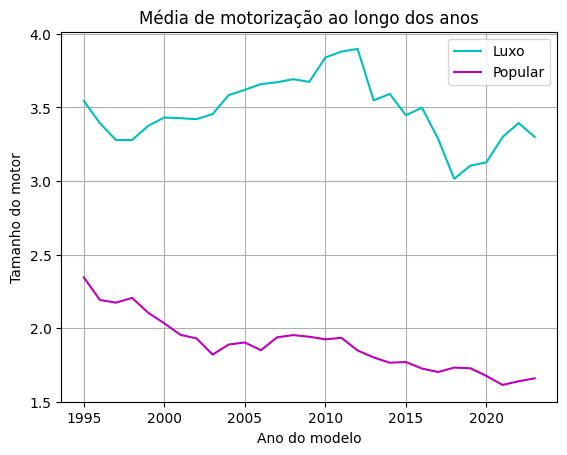

In [ ]:
# Luxo vs popular: plot

plt.plot(x, y_lux, '-c', label='Luxo')
plt.plot(x, y_com, '-m', label='Popular')

plt.title('Média de motorização ao longo dos anos')
plt.xlabel("Ano do modelo")
plt.ylabel("Tamanho do motor")
plt.grid()
plt.legend()

plt.show()

In [ ]:
# LUXO

from sklearn.linear_model import LinearRegression

model_lux = LinearRegression()

model_lux.fit(np.array((range(len(x)))).reshape(-1, 1), y_lux.reshape(-1, 1))

print(f'Coeficiente: {model_lux.coef_}')
print(f'Interceptação: {model_lux.intercept_}')


Coeficiente: [[-0.00535962]]
Interceptação: [3.54828633]


In [ ]:
# POPULAR

from sklearn.linear_model import LinearRegression

model_com = LinearRegression()

model_com.fit(np.array((range(len(x)))).reshape(-1, 1), y_com.reshape(-1, 1))

print(f'Coeficiente: {model_com.coef_}')
print(f'Interceptação: {model_com.intercept_}')

Coeficiente: [[-0.02001677]]
Interceptação: [2.16782422]


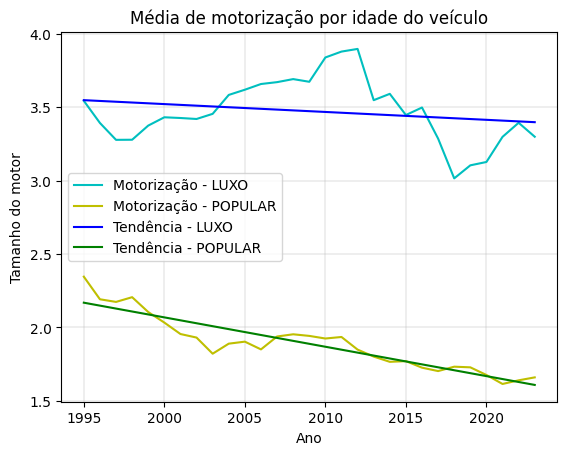

In [ ]:
# Plot com tendência

tend_lux = model_lux.coef_ * np.array(list(range(len(x)))).reshape(-1, 1) + model_lux.intercept_
tend_com = model_com.coef_ * np.array(list(range(len(x)))).reshape(-1, 1) + model_com.intercept_

plt.plot(x, y_lux, '-c', label='Motorização - LUXO')
plt.plot(x, y_com, '-y', label='Motorização - POPULAR')
plt.plot(x, tend_lux, '-b', label='Tendência - LUXO')
plt.plot(x, tend_com, '-g', label='Tendência - POPULAR')

plt.title('Média de motorização por idade do veículo')
plt.xlabel("Ano")
plt.ylabel("Tamanho do motor")
plt.grid(linewidth=0.3)
plt.legend()

plt.show()

In [ ]:
# LUXO

pred = model_lux.predict(np.array(49).reshape(1, -1))
print(f'A média de motorização esperada para o ano de 2033 é de {pred[0, 0]:.2f}.')

porc_menor = 1 - (pred[0, 0] / y_lux[8])
print(f'Em 2033, a motorização esperada é {(porc_menor * 100):.2f}% menor que em 1993, 40 anos atrás.')

A média de motorização esperada para o ano de 2033 é de 3.29.
Em 2033, a motorização esperada é 4.90% menor que em 1993, 40 anos atrás.


In [ ]:
# POPULAR

pred = model_com.predict(np.array(49).reshape(1, -1))
print(f'A média de motorização esperada para o ano de 2033 é de {pred[0, 0]:.2f}.')

porc_menor = 1 - (pred[0, 0] / y_com[8])
print(f'Em 2033, a motorização esperada é {(porc_menor * 100):.2f}% menor que em 1993, 40 anos atrás.')

A média de motorização esperada para o ano de 2033 é de 1.19.
Em 2033, a motorização esperada é 34.79% menor que em 1993, 40 anos atrás.


### Pergunta 2

In [ ]:
# Como se comporta o preço médio ao longo dos anos de fabricação?

df.head()

,year_of_reference,month_of_reference,fipe_code,authentication,brand,model,fuel,gear,engine_size,year_model,avg_price_brl,age_years
0,2022,January,038001-6,vwmrywl5qs,Acura,NSX 3.0,Gasoline,manual,3.0,1995,43779.0,28
1,2022,January,038001-6,t9mt723qhz,Acura,NSX 3.0,Gasoline,manual,3.0,1994,42244.0,29
2,2022,January,038001-6,tr5wv4z21g,Acura,NSX 3.0,Gasoline,manual,3.0,1993,40841.0,30
3,2022,January,038001-6,s2xxsjz3mt,Acura,NSX 3.0,Gasoline,manual,3.0,1992,39028.0,31
4,2022,January,038001-6,rtm9gj7zk8,Acura,NSX 3.0,Gasoline,manual,3.0,1991,35678.0,32


In [ ]:
from sklearn.linear_model import LinearRegression

y_preco = []

for year in x:
    y_preco.append(df[df.year_model == year].avg_price_brl.mean())

x_preco = np.array(range(len(x))).reshape(-1, 1)
y_preco = np.array(y_preco).reshape(-1, 1)

model = LinearRegression()
model.fit(x_preco, y_preco)

print(f"Coeficiente: {model.coef_}")
print(f"Interceptação: {model.intercept_}")

Coeficiente: [[12257.31634868]]
Interceptação: [-53189.39472979]


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

poly = PolynomialFeatures(degree=3, include_bias=False)
poly_features = poly.fit_transform(x_preco)

reg = LinearRegression()
reg.fit(poly_features, y_preco)

poly_curve = reg.predict(poly_features)

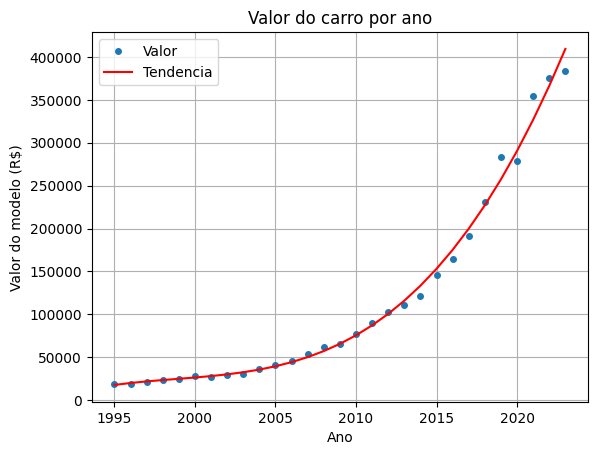

In [ ]:
plt.plot(x, y_preco, label='Valor', marker='o', ms=4, linestyle='')
plt.plot(x, poly_curve, label='Tendencia', color='r')
plt.title('Valor do carro por ano')
plt.xlabel('Ano')
plt.ylabel('Valor do modelo (R$)')
plt.legend()
plt.grid()
plt.show()

In [ ]:
pred = reg.predict(poly.transform(np.array(49).reshape(1, -1)))
print(f'A média de preço esperada para o ano de 2033 é de R$ {pred[0, 0]:.2f}.')

porc_menor = (pred[0, 0] / y_preco[19]) * 100 - 100
print(f'Em 2033, o preço esperado é {(porc_menor[0]):.2f}% maior do que o preço de modelos de 2013, 20 anos atrás.')

A média de preço esperada para o ano de 2033 é de R$ 2366561.64.
Em 2033, o preço esperado é 1849.20% maior do que o preço de modelos de 2013, 20 anos atrás.


### Pergunta 3

In [ ]:
# Como se comporta o preço por motorização ao longo dos anos de fabricação?

df.head()

,year_of_reference,month_of_reference,fipe_code,authentication,brand,model,fuel,gear,engine_size,year_model,avg_price_brl,age_years
0,2022,January,038001-6,vwmrywl5qs,Acura,NSX 3.0,Gasoline,manual,3.0,1995,43779.0,28
1,2022,January,038001-6,t9mt723qhz,Acura,NSX 3.0,Gasoline,manual,3.0,1994,42244.0,29
2,2022,January,038001-6,tr5wv4z21g,Acura,NSX 3.0,Gasoline,manual,3.0,1993,40841.0,30
3,2022,January,038001-6,s2xxsjz3mt,Acura,NSX 3.0,Gasoline,manual,3.0,1992,39028.0,31
4,2022,January,038001-6,rtm9gj7zk8,Acura,NSX 3.0,Gasoline,manual,3.0,1991,35678.0,32


In [ ]:
from sklearn.linear_model import LinearRegression

df_luxury['preco_por_motor'] = df_luxury['avg_price_brl'] / df_luxury['engine_size']
df_common['preco_por_motor'] = df_common['avg_price_brl'] / df_common['engine_size']

y_precomotor_lux = []
y_precomotor_com = []

for year in x:
    y_precomotor_lux.append(df_luxury[df_luxury.year_model == year].preco_por_motor.mean())
    y_precomotor_com.append(df_common[df_common.year_model == year].preco_por_motor.mean())

y_precomotor_lux = np.array(y_precomotor_lux).reshape(-1, 1)
y_precomotor_com = np.array(y_precomotor_com).reshape(-1, 1)

/tmp/ipykernel_727/1444876023.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_luxury['preco_por_motor'] = df_luxury['avg_price_brl'] / df_luxury['engine_size']
/tmp/ipykernel_727/1444876023.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_common['preco_por_motor'] = df_common['avg_price_brl'] / df_common['engine_size']


In [ ]:
# model_lux = LinearRegression()
# model_lux.fit(x_, y_precomotor)

# print(f"Coeficiente: {model.coef_}")
# print(f"Interceptação: {model.intercept_}")

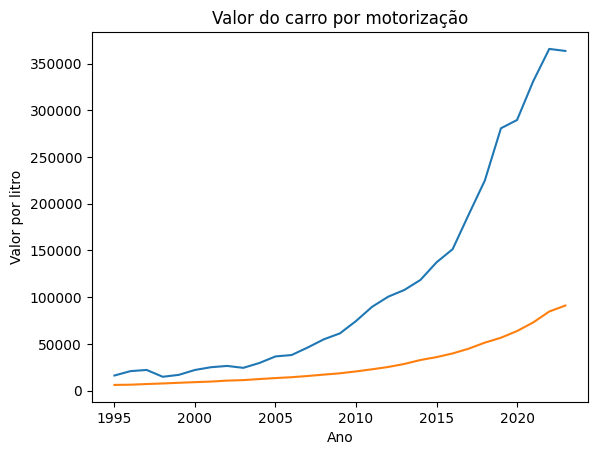

In [ ]:
plt.plot(x, y_precomotor_lux)
plt.plot(x, y_precomotor_com)

plt.title('Valor do carro por motorização')
plt.xlabel('Ano')
plt.ylabel('Valor por litro')
plt.show()

In [ ]:
# Vamos plotar o valor das diferenças em 2000, 2010 e 2020

diffs = [(x1 - x2) for x1, x2 in list(zip(y_precomotor_lux, y_precomotor_com))[4::10]]
diffs_ptg = [((x1 / x2) * 100 - 100) for x1, x2 in list(zip(y_precomotor_lux, y_precomotor_com))[4::10]]
diffs_def = []

for diff in diffs_ptg:
    diffs_def.append(diff[0])

x_diffs = [2000, 2010, 2020]

In [ ]:
diffs_def

[np.float64(100.42833143163384),
 np.float64(229.68467709153407),
 np.float64(395.58365222432786)]

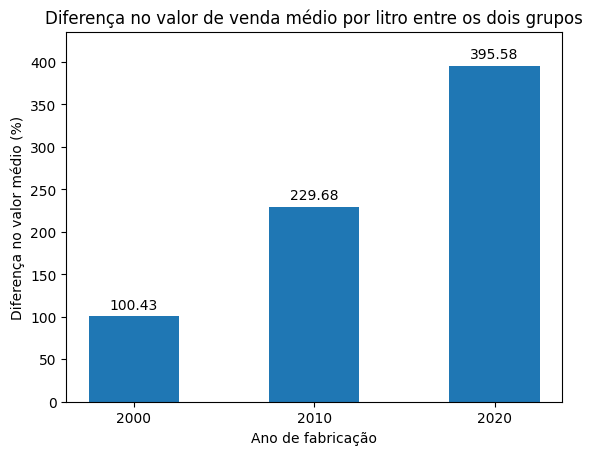

In [ ]:
x_diffs = [str(z) for z in x_diffs]
diffs_def = [round(float(z), 2) for z in diffs_def]

bars = plt.bar(x_diffs, diffs_def, width=0.5)
plt.bar_label(bars, padding=3)
plt.title('Diferença no valor de venda médio por litro entre os dois grupos')
plt.xlabel('Ano de fabricação')
plt.ylabel('Diferença no valor médio (%)')
plt.margins(y=0.1)
plt.show()

### Pergunta 4

In [ ]:
df.gear.unique()

array(['manual', 'automatic'], dtype=object)

In [ ]:
# Os carros manuais perderam mais valor se comparados aos automáticos?

man = df[df.gear == 'manual']
auto = df[df.gear == 'automatic']

y_man, y_auto = [], []

for year in x:
    y_man.append(man[man.year_model == year].avg_price_brl.mean())
    y_auto.append(auto[auto.year_model == year].avg_price_brl.mean())

y_man, y_auto = np.array(y_man[6:]).reshape(-1, 1), np.array(y_auto[6:]).reshape(-1, 1)

model_man = LinearRegression()
model_auto = LinearRegression()

model_man.fit(x_[6:], y_man)
model_auto.fit(x_[6:], y_auto)

print(f"Coeficiente MAN: {model_man.coef_}")
print(f"Interceptação MAN: {model_man.intercept_}")

print(f"Coeficiente AUTO: {model_auto.coef_}")
print(f"Interceptação AUTO: {model_auto.intercept_}")

Coeficiente MAN: [[19660.48855532]]
Interceptação MAN: [-174823.99472873]
Coeficiente AUTO: [[13387.2787969]]
Interceptação AUTO: [-99000.91131452]


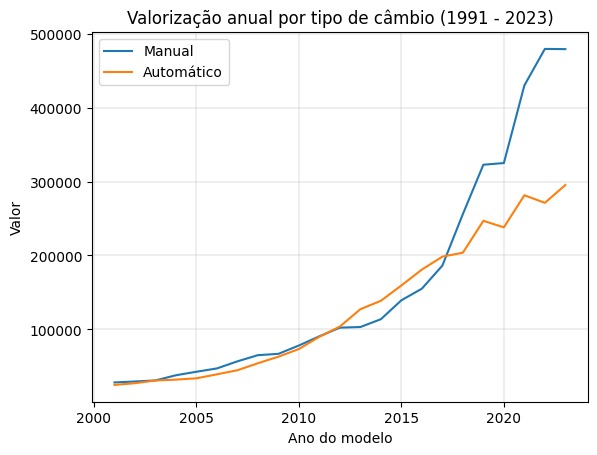

In [ ]:
plt.plot(x[6:], y_man, label='Manual')
plt.plot(x[6:], y_auto, label='Automático')
plt.xlabel('Ano do modelo')
plt.ylabel('Valor')
plt.title('Valorização anual por tipo de câmbio (1991 - 2023)')
plt.legend()
plt.grid(linewidth=0.3)
plt.show()

In [ ]:
# Os carros manuais perderam mais valor se comparados aos automáticos - LUXO?

man = df_luxury[df_luxury.gear == 'manual']
auto = df_luxury[df_luxury.gear == 'automatic']

y_man, y_auto = [], []

for year in x:
    y_man.append(man[man.year_model == year].avg_price_brl.mean())
    y_auto.append(auto[auto.year_model == year].avg_price_brl.mean())

y_man, y_auto = np.array(y_man[6:]).reshape(-1, 1), np.array(y_auto[6:]).reshape(-1, 1)

model_man = LinearRegression()
model_auto = LinearRegression()

model_man.fit(x_[6:], y_man)
model_auto.fit(x_[6:], y_auto)

print(f"Coeficiente MAN: {model_man.coef_}")
print(f"Interceptação MAN: {model_man.intercept_}")

print(f"Coeficiente AUTO: {model_auto.coef_}")
print(f"Interceptação AUTO: {model_auto.intercept_}")

Coeficiente MAN: [[69563.95031046]]
Interceptação MAN: [-576443.95443874]
Coeficiente AUTO: [[43131.41373157]]
Interceptação AUTO: [-398190.65471771]


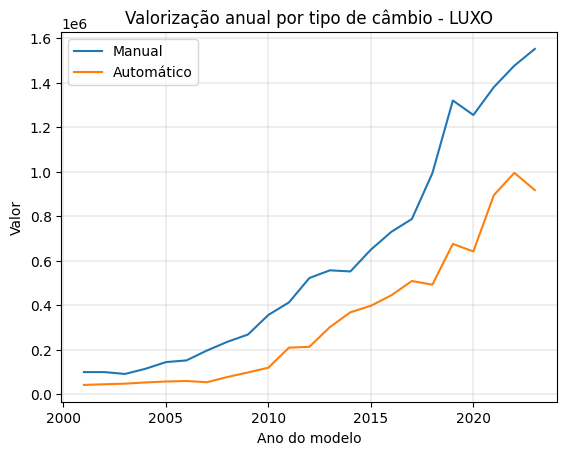

In [ ]:
plt.plot(x[6:], y_man, label='Manual')
plt.plot(x[6:], y_auto, label='Automático')
plt.xlabel('Ano do modelo')
plt.ylabel('Valor')
plt.title('Valorização anual por tipo de câmbio - LUXO')
plt.legend()
plt.grid(linewidth=0.3)
plt.show()

In [ ]:
# Os carros manuais perderam mais valor se comparados aos automáticos? - POPULAR

man = df_common[df_common.gear == 'manual']
auto = df_common[df_common.gear == 'automatic']

y_man, y_auto = [], []

for year in x:
    y_man.append(man[man.year_model == year].avg_price_brl.mean())
    y_auto.append(auto[auto.year_model == year].avg_price_brl.mean())

y_man, y_auto = np.array(y_man[6:]).reshape(-1, 1), np.array(y_auto[6:]).reshape(-1, 1)

model_man = LinearRegression()
model_auto = LinearRegression()

model_man.fit(x_[6:], y_man)
model_auto.fit(x_[6:], y_auto)

print(f"Coeficiente MAN: {model_man.coef_}")
print(f"Interceptação MAN: {model_man.intercept_}")

print(f"Coeficiente AUTO: {model_auto.coef_}")
print(f"Interceptação AUTO: {model_auto.intercept_}")

Coeficiente MAN: [[4904.64575256]]
Interceptação MAN: [-25071.31596571]
Coeficiente AUTO: [[6358.17535685]]
Interceptação AUTO: [-42561.00292381]


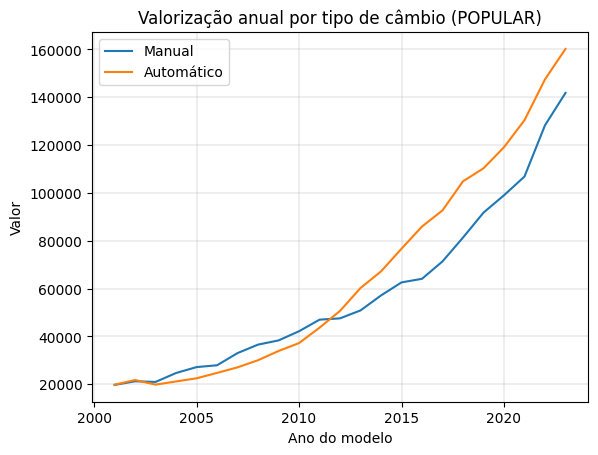

In [ ]:
plt.plot(x[6:], y_man, label='Manual')
plt.plot(x[6:], y_auto, label='Automático')
plt.xlabel('Ano do modelo')
plt.ylabel('Valor')
plt.title('Valorização anual por tipo de câmbio (POPULAR)')
plt.legend()
plt.grid(linewidth=0.3)
plt.show()

### Pergunta 6

In [ ]:
# Como se comporta a depreciação média dos carros a gasolina em relação aos carros diesel?

df.head()

,year_of_reference,month_of_reference,fipe_code,authentication,brand,model,fuel,gear,engine_size,year_model,avg_price_brl,age_years
0,2022,January,038001-6,vwmrywl5qs,Acura,NSX 3.0,Gasoline,manual,3.0,1995,43779.0,28
1,2022,January,038001-6,t9mt723qhz,Acura,NSX 3.0,Gasoline,manual,3.0,1994,42244.0,29
2,2022,January,038001-6,tr5wv4z21g,Acura,NSX 3.0,Gasoline,manual,3.0,1993,40841.0,30
3,2022,January,038001-6,s2xxsjz3mt,Acura,NSX 3.0,Gasoline,manual,3.0,1992,39028.0,31
4,2022,January,038001-6,rtm9gj7zk8,Acura,NSX 3.0,Gasoline,manual,3.0,1991,35678.0,32


In [ ]:
y_lux_gas, y_lux_die, y_lux_alc = [], [], []

for ano in x:
    y_lux_gas.append(df_luxury[(df_luxury.year_model == ano) & ((df_luxury.fuel == 'Gasoline') | (df_luxury.fuel == 'Alcohol'))].avg_price_brl.mean())
    y_lux_die.append(df_luxury[(df_luxury.year_model == ano) & (df_luxury.fuel == 'Diesel')].avg_price_brl.mean())

y_lux_gas = np.array(y_lux_gas).reshape(-1, 1)
y_lux_die = np.array(y_lux_die).reshape(-1, 1)


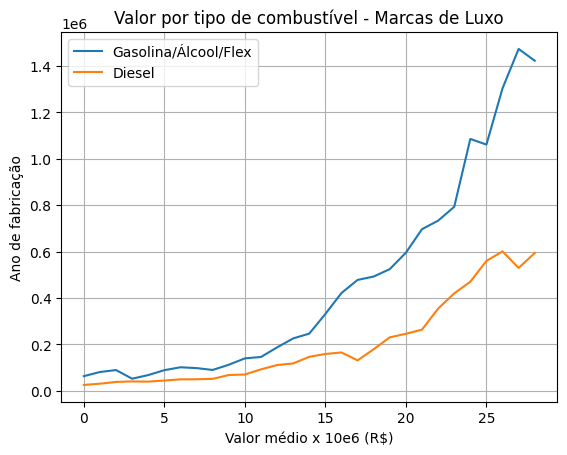

In [ ]:
plt.plot(x_, y_lux_gas, label='Gasolina/Álcool/Flex')
plt.plot(x_, y_lux_die, label='Diesel')
plt.title('Valor por tipo de combustível - Marcas de Luxo')
plt.grid()
plt.xlabel('Valor médio x 10e6 (R$)')
plt.ylabel('Ano de fabricação')
plt.legend()
plt.show()

In [ ]:
# POPULAR

y_com_gas, y_com_die, y_com_alc = [], [], []

for ano in x:
    y_com_gas.append(df_common[(df_common.year_model == ano) & ((df_common.fuel == 'Gasoline') | (df_common.fuel == 'Alcohol'))].avg_price_brl.mean())
    y_com_die.append(df_common[(df_common.year_model == ano) & (df_common.fuel == 'Diesel')].avg_price_brl.mean())

y_com_gas = np.array(y_com_gas).reshape(-1, 1)
y_com_die = np.array(y_lux_die).reshape(-1, 1)

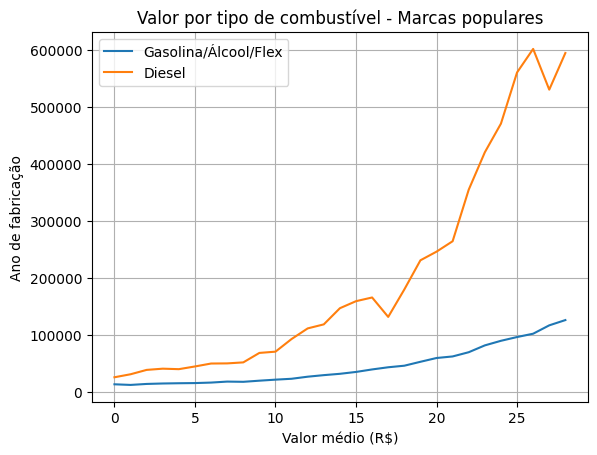

In [ ]:
plt.plot(x_, y_com_gas, label='Gasolina/Álcool/Flex')
plt.plot(x_, y_com_die, label='Diesel')
plt.title('Valor por tipo de combustível - Marcas populares')
plt.grid()
plt.xlabel('Valor médio (R$)')
plt.ylabel('Ano de fabricação')
plt.legend()
plt.show()